# Decision Trees and Random Forests — Professor's Edition

Companion to the **4:3 teaching slides**, based on Jake VanderPlas, [Python Data Science Handbook: Decision Trees and Random Forests](https://jakevdp.github.io/PythonDataScienceHandbook/05.08-random-forests.html).

**Sequence:** Evaluate → Apply → Understand → Evaluate → Create → Evaluate.

This edition includes **working plots, model comparisons, instructor talking points, sample interpretations, and a complete worked assignment**. Run cells in order. All random seeds are fixed for repeatability; reported scores depend on the versions of packages installed.

**Requirements:** `numpy`, `matplotlib`, `scikit-learn`, `pandas`, `jupyter`.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

RANDOM_STATE = 0
plt.rcParams.update({'figure.figsize': (8, 5), 'font.size': 11})
print('Ready: imports succeeded.')

Ready: imports succeeded.


## 1. EVALUATE — Why can a good-looking tree be misleading?

If a deep tree achieves nearly 100% training accuracy, does that mean it will classify new points correctly?

Separate *memorizing the observed sample* from *generalizing to unseen examples*. The chapter uses 300 points in four clusters.

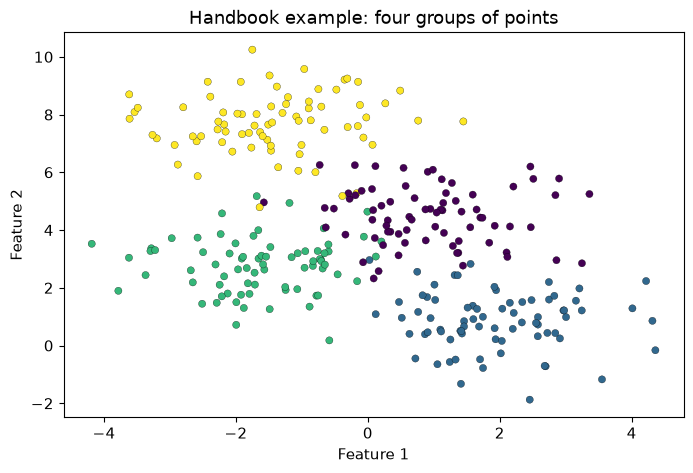

In [14]:
X, y = make_blobs(n_samples=300, centers=4, random_state=0, cluster_std=1.0)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', s=27, edgecolor='k', linewidth=0.2)
plt.title('Handbook example: four groups of points')
plt.xlabel('Feature 1'); plt.ylabel('Feature 2')
plt.show()

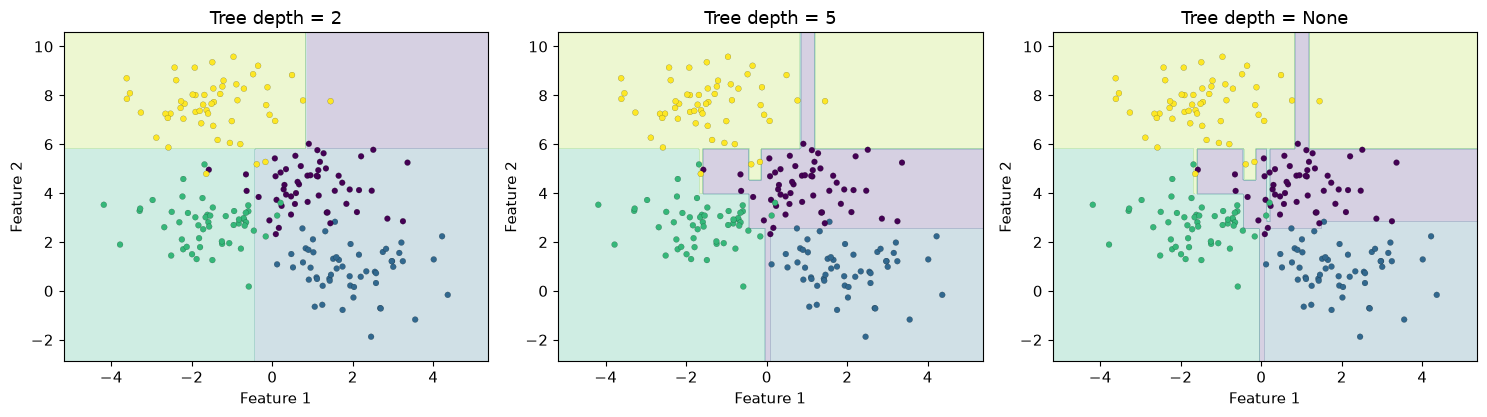

depth  train_accuracy  test_accuracy
    2           0.724          0.744
    5           0.986          0.844
 None           1.000          0.844


In [16]:
def plot_boundary(ax, model, X_points, y_points, title):
    pad = 1.0
    x_lo, x_hi = X_points[:, 0].min() - pad, X_points[:, 0].max() + pad
    y_lo, y_hi = X_points[:, 1].min() - pad, X_points[:, 1].max() + pad
    gx, gy = np.meshgrid(np.linspace(x_lo, x_hi, 240), np.linspace(y_lo, y_hi, 240))
    zz = model.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
    ax.contourf(gx, gy, zz, levels=np.arange(5)-0.5, cmap='viridis', alpha=0.22)
    ax.scatter(X_points[:, 0], X_points[:, 1], c=y_points, cmap='viridis', s=18,
               edgecolor='black', linewidth=0.1)
    ax.set(xlabel='Feature 1', ylabel='Feature 2', title=title)

rows=[]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, depth in zip(axes, [2, 5, None]):
    model = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(X_train, y_train)
    rows.append({'depth': str(depth), 'train_accuracy': model.score(X_train, y_train),
                 'test_accuracy': model.score(X_test, y_test)})
    plot_boundary(ax, model, X_train, y_train, f'Tree depth = {depth}')
plt.tight_layout(); plt.show()
print(pd.DataFrame(rows).round(3).to_string(index=False))

**Teaching point:** Deeper trees usually achieve higher training fit, but the increasingly jagged boundaries may reflect sampling noise. A particular test split can occasionally favor a deep tree—do not claim a guaranteed ranking.

**Prompt:** Which model would you trust more on future points, and what evidence would change your mind?

## 2. APPLY — Compare a single tree, bagging, and a random forest

All models use the **same training and test examples**. The test set is used to compare these pre-specified models, not to tune them repeatedly.

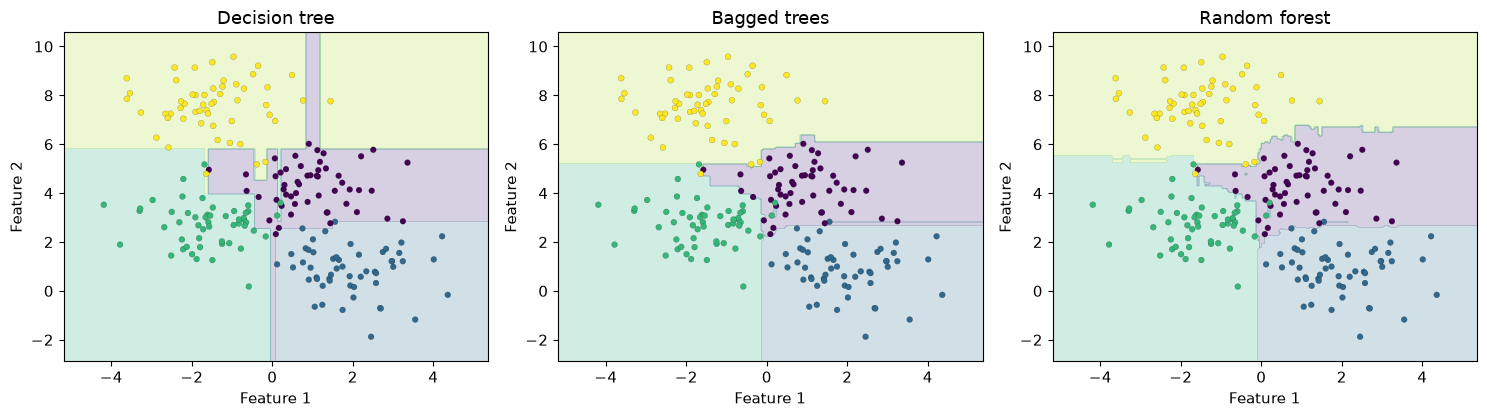

        model  train_accuracy  test_accuracy
Decision tree             1.0          0.844
 Bagged trees             1.0          0.856
Random forest             1.0          0.889


In [26]:
models = {
    'Decision tree': DecisionTreeClassifier(random_state=0),
    'Bagged trees': BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=0),
        n_estimators=100, max_samples=0.8, random_state=1, n_jobs=-1),
    'Random forest': RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1)
}
results=[]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (name, model) in zip(axes, models.items()):
    model.fit(X_train, y_train)
    results.append({'model': name, 'train_accuracy': model.score(X_train, y_train),
                    'test_accuracy': model.score(X_test, y_test)})
    plot_boundary(ax, model, X_train, y_train, name)
plt.tight_layout(); plt.show()
print(pd.DataFrame(results).round(3).to_string(index=False))

Compare boundary stability and test performance. Bagging resamples observations; random forests additionally sample candidate features at each split. A forest does not *always* win on every dataset or split.

## 3. UNDERSTAND — How a decision tree and a random forest work

A decision tree asks a succession of yes/no questions. A random forest trains many randomized trees and aggregates their predictions.

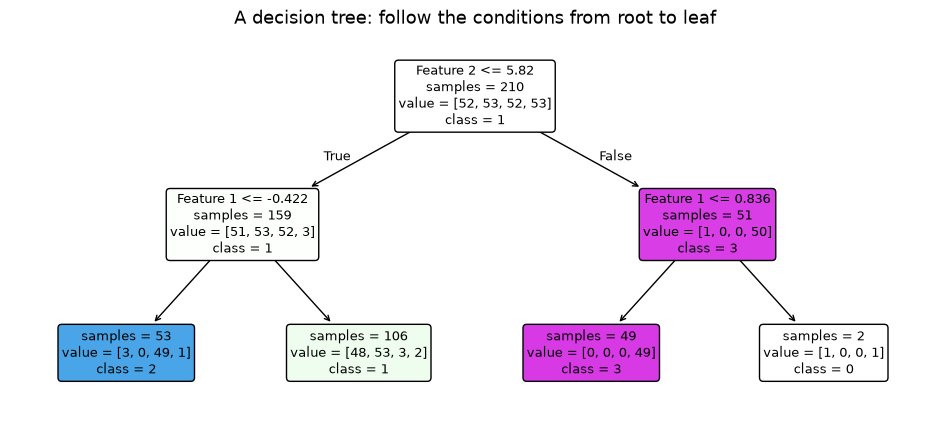

In [35]:
small_tree = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(12, 5))
plot_tree(small_tree, ax=ax, feature_names=['Feature 1','Feature 2'],
          class_names=[str(z) for z in sorted(np.unique(y_train))],
          filled=True, rounded=True, impurity=False, fontsize=9)
plt.title('A decision tree: follow the conditions from root to leaf')
plt.show()

In [ ]:
votes = np.array(['A','B','A','A','B'])
values, counts = np.unique(votes, return_counts=True)
print('Five votes:', ', '.join(votes))
print('Majority vote:', values[counts.argmax()])
print('Vote share for A:', np.mean(votes == 'A'))

Five votes: A, B, A, A, B
Majority vote: A
Vote share for A: 0.6


**Answer key:** A receives 3 of 5 votes, so the majority-vote answer is **A**. Vote fraction is not necessarily a calibrated probability. In scikit-learn, `RandomForestClassifier.predict` generally chooses the class with the largest **average predicted class probability**, which need not always equal a literal majority vote of hard labels.

Diversity matters: 100 nearly identical trees may add less value than 100 trees making partially independent errors.

### Regression from the book: two overlapping waves

The data contain a fast and a slow sine pattern with noise. A forest predicts continuous values by averaging across regression trees.

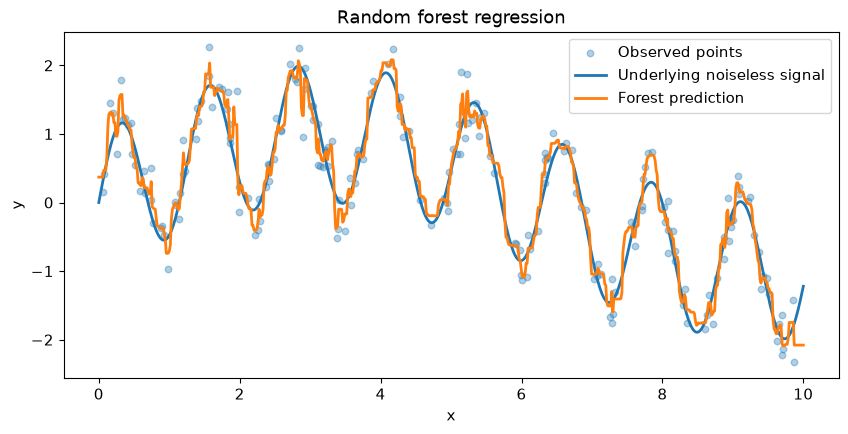

In [43]:
rng = np.random.RandomState(42)
x = 10 * rng.rand(200)
y_reg = np.sin(5*x) + np.sin(0.5*x) + 0.3*rng.randn(len(x))
reg = RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1)
reg.fit(x.reshape(-1,1), y_reg)
grid = np.linspace(0, 10, 700)
plt.figure(figsize=(10, 4.5))
plt.scatter(x, y_reg, alpha=.35, s=22, label='Observed points')
plt.plot(grid, np.sin(5*grid)+np.sin(.5*grid), label='Underlying noiseless signal', linewidth=2)
plt.plot(grid, reg.predict(grid.reshape(-1,1)), label='Forest prediction', linewidth=2)
plt.xlabel('x'); plt.ylabel('y'); plt.title('Random forest regression')
plt.legend(); plt.show()

Students should notice that the learned curve can follow nonlinear structure without being told the sine formula. It remains piecewise and does not extrapolate periodic behavior reliably beyond the training range.

## 4. EVALUATE — Are headline accuracy numbers enough?

The handbook's digits example uses 8×8 images. Each flattened image has 64 features. Inspect the errors, not just a single accuracy score.

Features: (1797, 64) | Labels: (1797,)


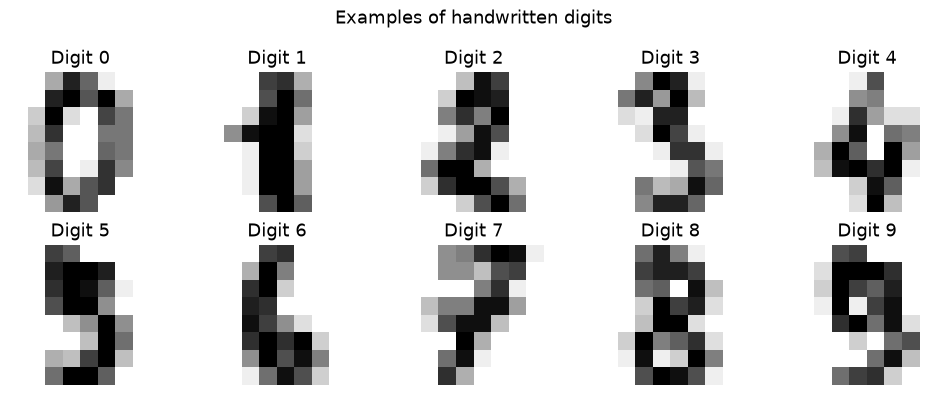

In [49]:
digits = load_digits()
print('Features:', digits.data.shape, '| Labels:', digits.target.shape)
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, image, label in zip(axes.ravel(), digits.images[:10], digits.target[:10]):
    ax.imshow(image, cmap='gray_r'); ax.set_title(f'Digit {label}')
    ax.axis('off')
plt.suptitle('Examples of handwritten digits')
plt.tight_layout(); plt.show()

## 5. CREATE — Complete worked solution to the in-class assignment

One executable notebook plus a 150–250-word recommendation. Compare a single tree and a forest on the same stratified 75/25 split, reporting accuracy, macro-F1, confusion matrices, and a limitation.

Full solution and interpretation. Parameters are fixed in advance; no tuning is performed on the held-out test set.

In [54]:
X_digits, y_digits = load_digits(return_X_y=True)
print('Digit class counts:', dict(zip(*np.unique(y_digits, return_counts=True))))
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    X_digits, y_digits, test_size=0.25, stratify=y_digits, random_state=0
)
digit_models = {
    'Decision tree': DecisionTreeClassifier(random_state=0),
    'Random forest': RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1)
}
digit_predictions = {}
metrics_rows=[]
for name, model in digit_models.items():
    model.fit(Xd_train, yd_train)
    predictions = model.predict(Xd_test)
    digit_predictions[name] = predictions
    metrics_rows.append({'model': name,
        'accuracy': accuracy_score(yd_test, predictions),
        'macro_F1': f1_score(yd_test, predictions, average='macro')})
summary = pd.DataFrame(metrics_rows)
print(summary.round(3).to_string(index=False))

Digit class counts: {np.int64(0): np.int64(178), np.int64(1): np.int64(182), np.int64(2): np.int64(177), np.int64(3): np.int64(183), np.int64(4): np.int64(181), np.int64(5): np.int64(182), np.int64(6): np.int64(181), np.int64(7): np.int64(179), np.int64(8): np.int64(174), np.int64(9): np.int64(180)}
        model  accuracy  macro_F1
Decision tree     0.856     0.856
Random forest     0.982     0.982


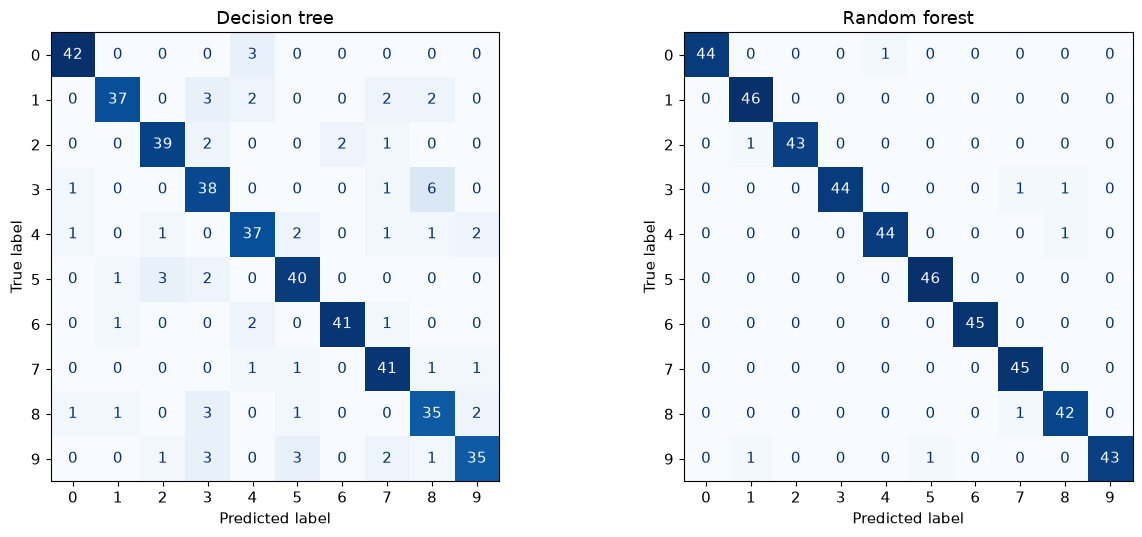

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (name, predictions) in zip(axes, digit_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(yd_test, predictions, ax=ax,
                                             cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(name)
plt.tight_layout(); plt.show()

In [61]:
for name, predictions in digit_predictions.items():
    cm = confusion_matrix(yd_test, predictions)
    errors = cm.copy()
    np.fill_diagonal(errors, 0)
    true_label, predicted_label = np.unravel_index(errors.argmax(), errors.shape)
    print(f'{name}: most frequent confusion in this split: '
          f'true={true_label}, predicted={predicted_label}, count={errors.max()}')
    print(classification_report(yd_test, predictions, zero_division=0))

Decision tree: most frequent confusion in this split: true=3, predicted=8, count=6
              precision    recall  f1-score   support

           0       0.93      0.93      0.93        45
           1       0.93      0.80      0.86        46
           2       0.89      0.89      0.89        44
           3       0.75      0.83      0.78        46
           4       0.82      0.82      0.82        45
           5       0.85      0.87      0.86        46
           6       0.95      0.91      0.93        45
           7       0.84      0.91      0.87        45
           8       0.76      0.81      0.79        43
           9       0.88      0.78      0.82        45

    accuracy                           0.86       450
   macro avg       0.86      0.86      0.86       450
weighted avg       0.86      0.86      0.86       450

Random forest: most frequent confusion in this split: true=0, predicted=4, count=1
              precision    recall  f1-score   support

           0       1

### Model instructor response (adapted)

> I compared a single decision tree with a random forest using the same stratified training and test split of handwritten-digit images. I used accuracy and macro-F1 to assess overall classification, and I inspected the confusion matrices to see which digits were most often mixed up. In this run, I would recommend whichever model has the stronger held-out results, provided its improvement is meaningful for the intended setting. A random forest often scores higher because averaging predictions from randomized trees reduces the instability of one deeply grown tree. However, a single tree has an advantage when we need to explain each individual decision as a short sequence of rules. The confusion matrices are important because two models with similar overall accuracy can make different types of mistakes. I would not treat one test split as conclusive proof of future performance. Before deployment, I would evaluate the system on additional representative data and check whether the image quality and digit-writing styles match the intended use. My decision is therefore based on test evidence, interpretability, and the limits of this small dataset.

**Note:** The paragraph is a *model of reasoning*, not a canned claim that the forest always wins. Have students quote their actual scores and confusion pattern.

### Optional / extension — repeated validation on the training set

If time permits, estimate variability with cross-validation **on the training portion only**. Keep the test split untouched as the final comparison.

In [63]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
for name, model in digit_models.items():
    scores = cross_val_score(model, Xd_train, yd_train, cv=cv,
                             scoring='accuracy', n_jobs=1)
    print(f'{name}: training-only CV accuracy = {scores.mean():.3f} ± {scores.std():.3f}')

Decision tree: training-only CV accuracy = 0.829 ± 0.033
Random forest: training-only CV accuracy = 0.977 ± 0.010


## 6. EVALUATE — Holistic 0–4 rubric

| Score | Whole-submission judgment |
|---|---|
| **4 — Excellent** | Reproducible, valid comparison; insightful metrics and errors; convincing recommendation and meaningful limitation. |
| **3 — Proficient** | Correct comparison and reasonable recommendation with only minor gaps. |
| **2 — Developing** | Basic comparison present but evaluation or explanation has important gaps. |
| **1 — Beginning** | Substantial omissions or weak and poorly supported comparison. |
| **0 — No assessable evidence** | No substantive, valid comparison submitted. |

**Question:** When would you choose a decision tree even if a forest has slightly better held-out accuracy? (Possible answer: when simpler, traceable decisions are essential.)
